# TD — Régression logistique : effet de l'âge, du sexe et des comorbidités sur la mortalité à 12 mois après un AVC — CORRIGÉ ENSEIGNANT

**Master 2 — SITIS** · Durée : **3 h**

---

## Contexte clinique

Après un AVC, une partie des patients décède dans l'année qui suit. Identifier les **facteurs présents dès l'admission** associés à ce décès permet d'adapter le suivi, d'identifier les profils à risque et de savoir sur quels facteurs ajuster dans les analyses pronostiques.

Dans le TD précédent (régression linéaire), la variable d'intérêt était **quantitative** (NIHSS à l'admission). Ici, la variable d'intérêt est **binaire** : le patient est-il décédé dans les 12 mois suivant son AVC (`death_within_12_months` = 1) ou non (= 0) ? Un modèle linéaire n'est plus adapté (une probabilité est bornée entre 0 et 1) : on utilise la **régression logistique**.

## Objectif du TD

> **Étudier l'effet de l'âge, du sexe et des comorbidités sur la mortalité à 12 mois après un AVC, à l'aide de modèles de régression logistique de complexité croissante.**

## Objectifs pédagogiques

À l'issue de ce TD, vous serez capables de :

1. Décrire un jeu de données pour une variable d'intérêt binaire et expliciter les hypothèses causales avec un **DAG** ;
2. Ajuster un modèle logistique avec une variable catégorielle, quantitative, ou les deux ;
3. **Interpréter chaque coefficient** : log-odds, odds ratio (OR), probabilité — et savoir passer de l'un à l'autre ;
4. Comprendre ce que devient un coefficient quand on **ajuste** sur une autre variable (confusion) ou qu'on ajoute une **interaction** ;
5. Tester l'ajout d'une variable avec le **test de Wald** et le **test du rapport de vraisemblance (LRT)**.

## Déroulé prévu (3 h)

| Partie | Contenu | Durée indicative |
|---|---|---|
| 0-2 | Import, contrôle qualité, description données| 20 min |
| 3 | DAG | 5 min |
| 4 | Rappels + régression logistique, **1 variable catégorielle** | 30 min |
| 5 | Régression logistique, **1 variable quantitative** | 30 min |
| 6 | **Catégorielle + quantitative, sans interaction** | 20 min |
| 7 | **Catégorielle + quantitative, avec interaction** | 25 min |
| 8 | **Ajout d'une variable** : Wald vs rapport de vraisemblance | 20 min |

> **Fil rouge de ce TD : l'interprétation des coefficients.** À chaque modèle, posez-vous : *« que représente exactement ce chiffre, pour quel patient, et à quelle échelle (log-odds, odds, probabilité) ? »*

## 0. Import des librairies

On utilise `statsmodels` (formules R-like, erreurs standards, IC, tests de Wald et vraisemblance disponibles) plutôt que `scikit-learn` (orienté prédiction, régularisé par défaut, pas d'inférence).

Deux **fonctions utilitaires** sont fournies pour la suite du TD :

- `tableau_or(modele)` : tableau des coefficients (log-odds) **et** des odds ratios avec leurs IC à 95 % ;
- `lrt(m0, m1)` : test du rapport de vraisemblance entre deux modèles emboîtés.

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.special import expit, logit   # expit(x) = 1/(1+exp(-x)) ; logit(p) = log(p/(1-p))
from IPython.display import Image, display

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (6, 4)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")

C1, C2 = "#2C3E50", "#E74C3C"


def tableau_or(modele, arrondi=3):
    """Coefficients (log-odds), odds ratios et IC95% d'un modèle logistique statsmodels."""
    ic = modele.conf_int()
    out = pd.DataFrame({
        "coef (log-odds)": modele.params,
        "OR = exp(coef)": np.exp(modele.params),
        "IC95% OR bas": np.exp(ic[0]),
        "IC95% OR haut": np.exp(ic[1]),
        "p-value (Wald)": modele.pvalues,
    })
    return out.round(arrondi)


def lrt(m0, m1):
    """Test du rapport de vraisemblance : m0 (modèle restreint) emboîté dans m1 (modèle complet)."""
    stat = 2 * (m1.llf - m0.llf)
    ddl = m1.df_model - m0.df_model
    p = stats.chi2.sf(stat, ddl)
    return pd.Series({"-2 log-vraisemblance m0": -2 * m0.llf,
                      "-2 log-vraisemblance m1": -2 * m1.llf,
                      "Statistique LRT": stat, "ddl": int(ddl), "p-value": p})

## 1. Importation et contrôle qualité

Le fichier `tbl_stroke.csv` (le même que pour le TD précédent) contient les données de **1203 patients** pris en charge pour un AVC.

| Variable | Type | Description |
|---|---|---|
| `patient_id` | id | Identifiant patient |
| `sex` | catégorielle | Sexe (`Male` / `Female`) |
| `age_at_inclusion` | continue | Âge à l'inclusion (années) |
| `hypertension`, `atrial_fibrillation`, `ischemic_heart_disease`, `diabetes`, `transient_ischemic_attack`, `chronic_kidney_disease` | binaires (0/1) | Comorbidités |
| `time_to_care_hours` | continue | Délai symptômes → prise en charge (h) |
| `stroke_location`, `stroke_size` | catégorielles | Caractéristiques de l'AVC |
| `NIHSS_admission`, `NIHSS_discharge`, `NIHSS_12_months` | continues | Sévérité neurologique (admission / sortie / 12 mois) |
| `stroke_within_12_months`, `myocardial_infarction_within_12_months` | binaires | Événements à 12 mois |
| **`death_within_12_months`** | **binaire (0/1)** | **Décès à 12 mois — variable d'intérêt (Y)** |

In [8]:
df = pd.read_csv("tbl_stroke.csv")
print(df.shape)
df.head()

(1203, 18)


,patient_id,sex,age_at_inclusion,hypertension,atrial_fibrillation,ischemic_heart_disease,diabetes,transient_ischemic_attack,chronic_kidney_disease,time_to_care_hours,stroke_location,stroke_size,NIHSS_admission,NIHSS_discharge,NIHSS_12_months,stroke_within_12_months,myocardial_infarction_within_12_months,death_within_12_months
0,1,Male,76.170,0,0,0,0,0,0,11,Lacunar,Small,10,0,0.000,1,0,0
1,2,Female,67.006,0,0,0,0,0,0,3,MCA,Medium,10,1,0.000,0,0,0
2,3,Male,52.222,1,0,0,0,0,0,1,Lacunar,Small,13,0,0.000,1,0,0
3,4,Male,60.389,1,0,0,1,0,0,3,Vertebro_basilar,Medium,16,10,0.000,1,0,0
4,5,Male,72.851,1,1,0,1,0,0,14,ACA,Medium,22,17,11.000,1,0,0


In [3]:
# Doublons et valeurs manquantes
print("Doublons patient_id :", df["patient_id"].duplicated().sum())
print("\nValeurs manquantes par variable :")
print(df.isna().sum()[df.isna().sum() > 0])

Doublons patient_id : 0

Valeurs manquantes par variable :
NIHSS_12_months    173
dtype: int64


`NIHSS_12_months` comporte des valeurs manquantes (patients décédés ? perdus de vue ?) mais cette variable **n'est pas utilisée** ici. Toutes les variables du modèle sont complètes.

On code `sex` en variable catégorielle avec **`Male` comme modalité de référence** : ce choix détermine l'interprétation de tous les coefficients qui font intervenir le sexe.

> **Exercice 1.** Vérifiez que `death_within_12_months` est bien codée 0/1, puis calculez le **nombre de décès** et la **proportion de décès** dans l'échantillon.

In [9]:
df["sex"] = pd.Categorical(df["sex"], categories=["Male", "Female"])
df["sex"].value_counts()

sex
Male      612
Female    591
Name: count, dtype: int64

In [ ]:
Y = "death_within_12_months"
# .value_counts() ; .mean()


death_within_12_months
0    1030
1     173
Name: count, dtype: int64
Nombre de décès : 173
Proportion de décès : 0.144


## 2. Description des données

### 2.1 Tableau descriptif selon le statut vital à 12 mois

Un Tableau 1 stratifié sur la variable d'intérêt est la première étape de toute analyse.

In [11]:
com = ["hypertension", "atrial_fibrillation", "ischemic_heart_disease",
       "diabetes", "transient_ischemic_attack", "chronic_kidney_disease"]
Y = "death_within_12_months"

lignes = []
vivants, decedes = df[df[Y] == 0], df[df[Y] == 1]

# Âge : moyenne (écart-type)
lignes.append({
    "Variable": "Âge, moy (ET)",
    f"Vivants (n={len(vivants)})": f"{vivants['age_at_inclusion'].mean():.1f} ({vivants['age_at_inclusion'].std():.1f})",
    f"Décédés (n={len(decedes)})": f"{decedes['age_at_inclusion'].mean():.1f} ({decedes['age_at_inclusion'].std():.1f})"
})

# Sexe et comorbidités : n (%)
for var, lab in [("sex", "Sexe féminin")] + [(c, c) for c in com]:
    x = (df[var] == "Female") if var == "sex" else (df[var] == 1)

    n_v = x[df[Y] == 0].sum()
    n_d = x[df[Y] == 1].sum()

    lignes.append({
        "Variable": lab + ", n (%)",
        f"Vivants (n={len(vivants)})": f"{n_v} ({100*n_v/len(vivants):.1f}%)",
        f"Décédés (n={len(decedes)})": f"{n_d} ({100*n_d/len(decedes):.1f}%)"
    })

# Tableau descriptif final
pd.DataFrame(lignes).set_index("Variable")


,Vivants (n=1030),Décédés (n=173)
Variable,,
"Âge, moy (ET)",73.3 (11.2),79.3 (9.7)
"Sexe féminin, n (%)",486 (47.2%),105 (60.7%)
"hypertension, n (%)",338 (32.8%),76 (43.9%)
"atrial_fibrillation, n (%)",139 (13.5%),52 (30.1%)
"ischemic_heart_disease, n (%)",285 (27.7%),86 (49.7%)
"diabetes, n (%)",373 (36.2%),110 (63.6%)
"transient_ischemic_attack, n (%)",12 (1.2%),4 (2.3%)
"chronic_kidney_disease, n (%)",95 (9.2%),42 (24.3%)


### 2.2 Graphiques : mortalité selon l'âge et selon le sexe

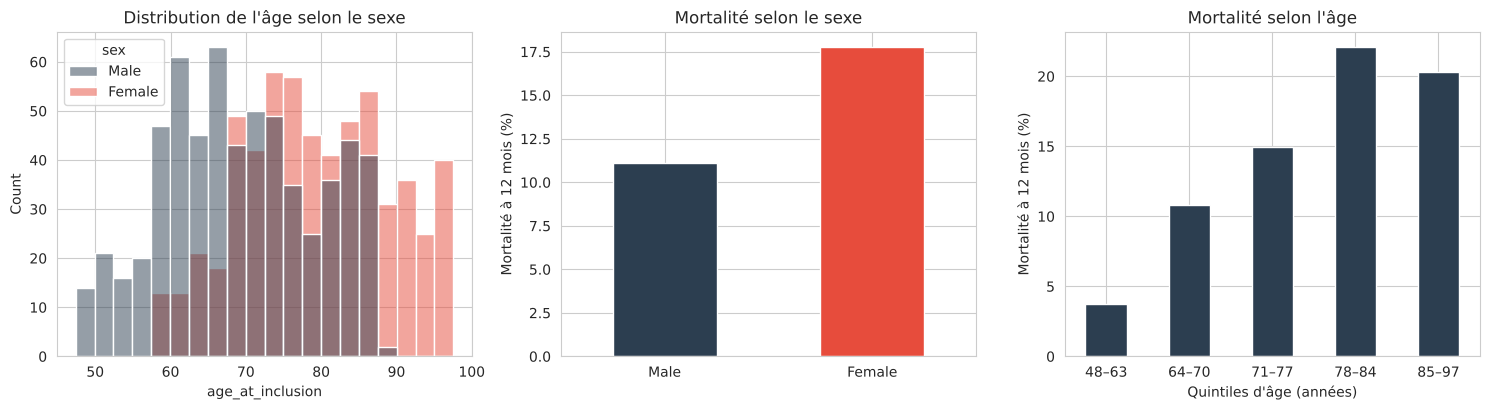

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

sns.histplot(data=df, x="age_at_inclusion", hue="sex", bins=20, multiple="layer",
             palette=[C1, C2], alpha=0.5, ax=axes[0])
axes[0].set_title("Distribution de l'âge selon le sexe")

df.groupby("sex", observed=True)[Y].mean().mul(100).plot(kind="bar", color=[C1, C2], ax=axes[1])
axes[1].set_ylabel("Mortalité à 12 mois (%)"); axes[1].set_xlabel("")
axes[1].set_title("Mortalité selon le sexe"); axes[1].tick_params(axis="x", rotation=0)

classes_age = pd.qcut(df["age_at_inclusion"], 5)
mort_age = df.groupby(classes_age, observed=True)[Y].mean().mul(100)
mort_age.index = [f"{int(i.left)+1}–{int(i.right)}" for i in mort_age.index]
mort_age.plot(kind="bar", color=C1, ax=axes[2])
axes[2].tick_params(axis="x", rotation=0)
axes[2].set_ylabel("Mortalité à 12 mois (%)"); axes[2].set_xlabel("Quintiles d'âge (années)")
axes[2].set_title("Mortalité selon l'âge")

plt.tight_layout(); plt.show()

> **Question 1.** Que remarquez-vous sur la mortalité selon le sexe ? Sur la distribution de l'âge selon le sexe ? Quelle hypothèse cela suggère-t-il pour la suite ?

> *Réponse :*


> **Question 2 (puissance).** Calculez aussi la répartition du sexe chez les patients ayant eu un antécédent d'AIT (`transient_ischemic_attack`) : que remarquez-vous ?

In [ ]:
#pd.crosstab()

transient_ischemic_attack     0   1   All
sex                                      
Male                        612   0   612
Female                      575  16   591
All                        1187  16  1203


> *Réponse :*


## 3. DAG associé


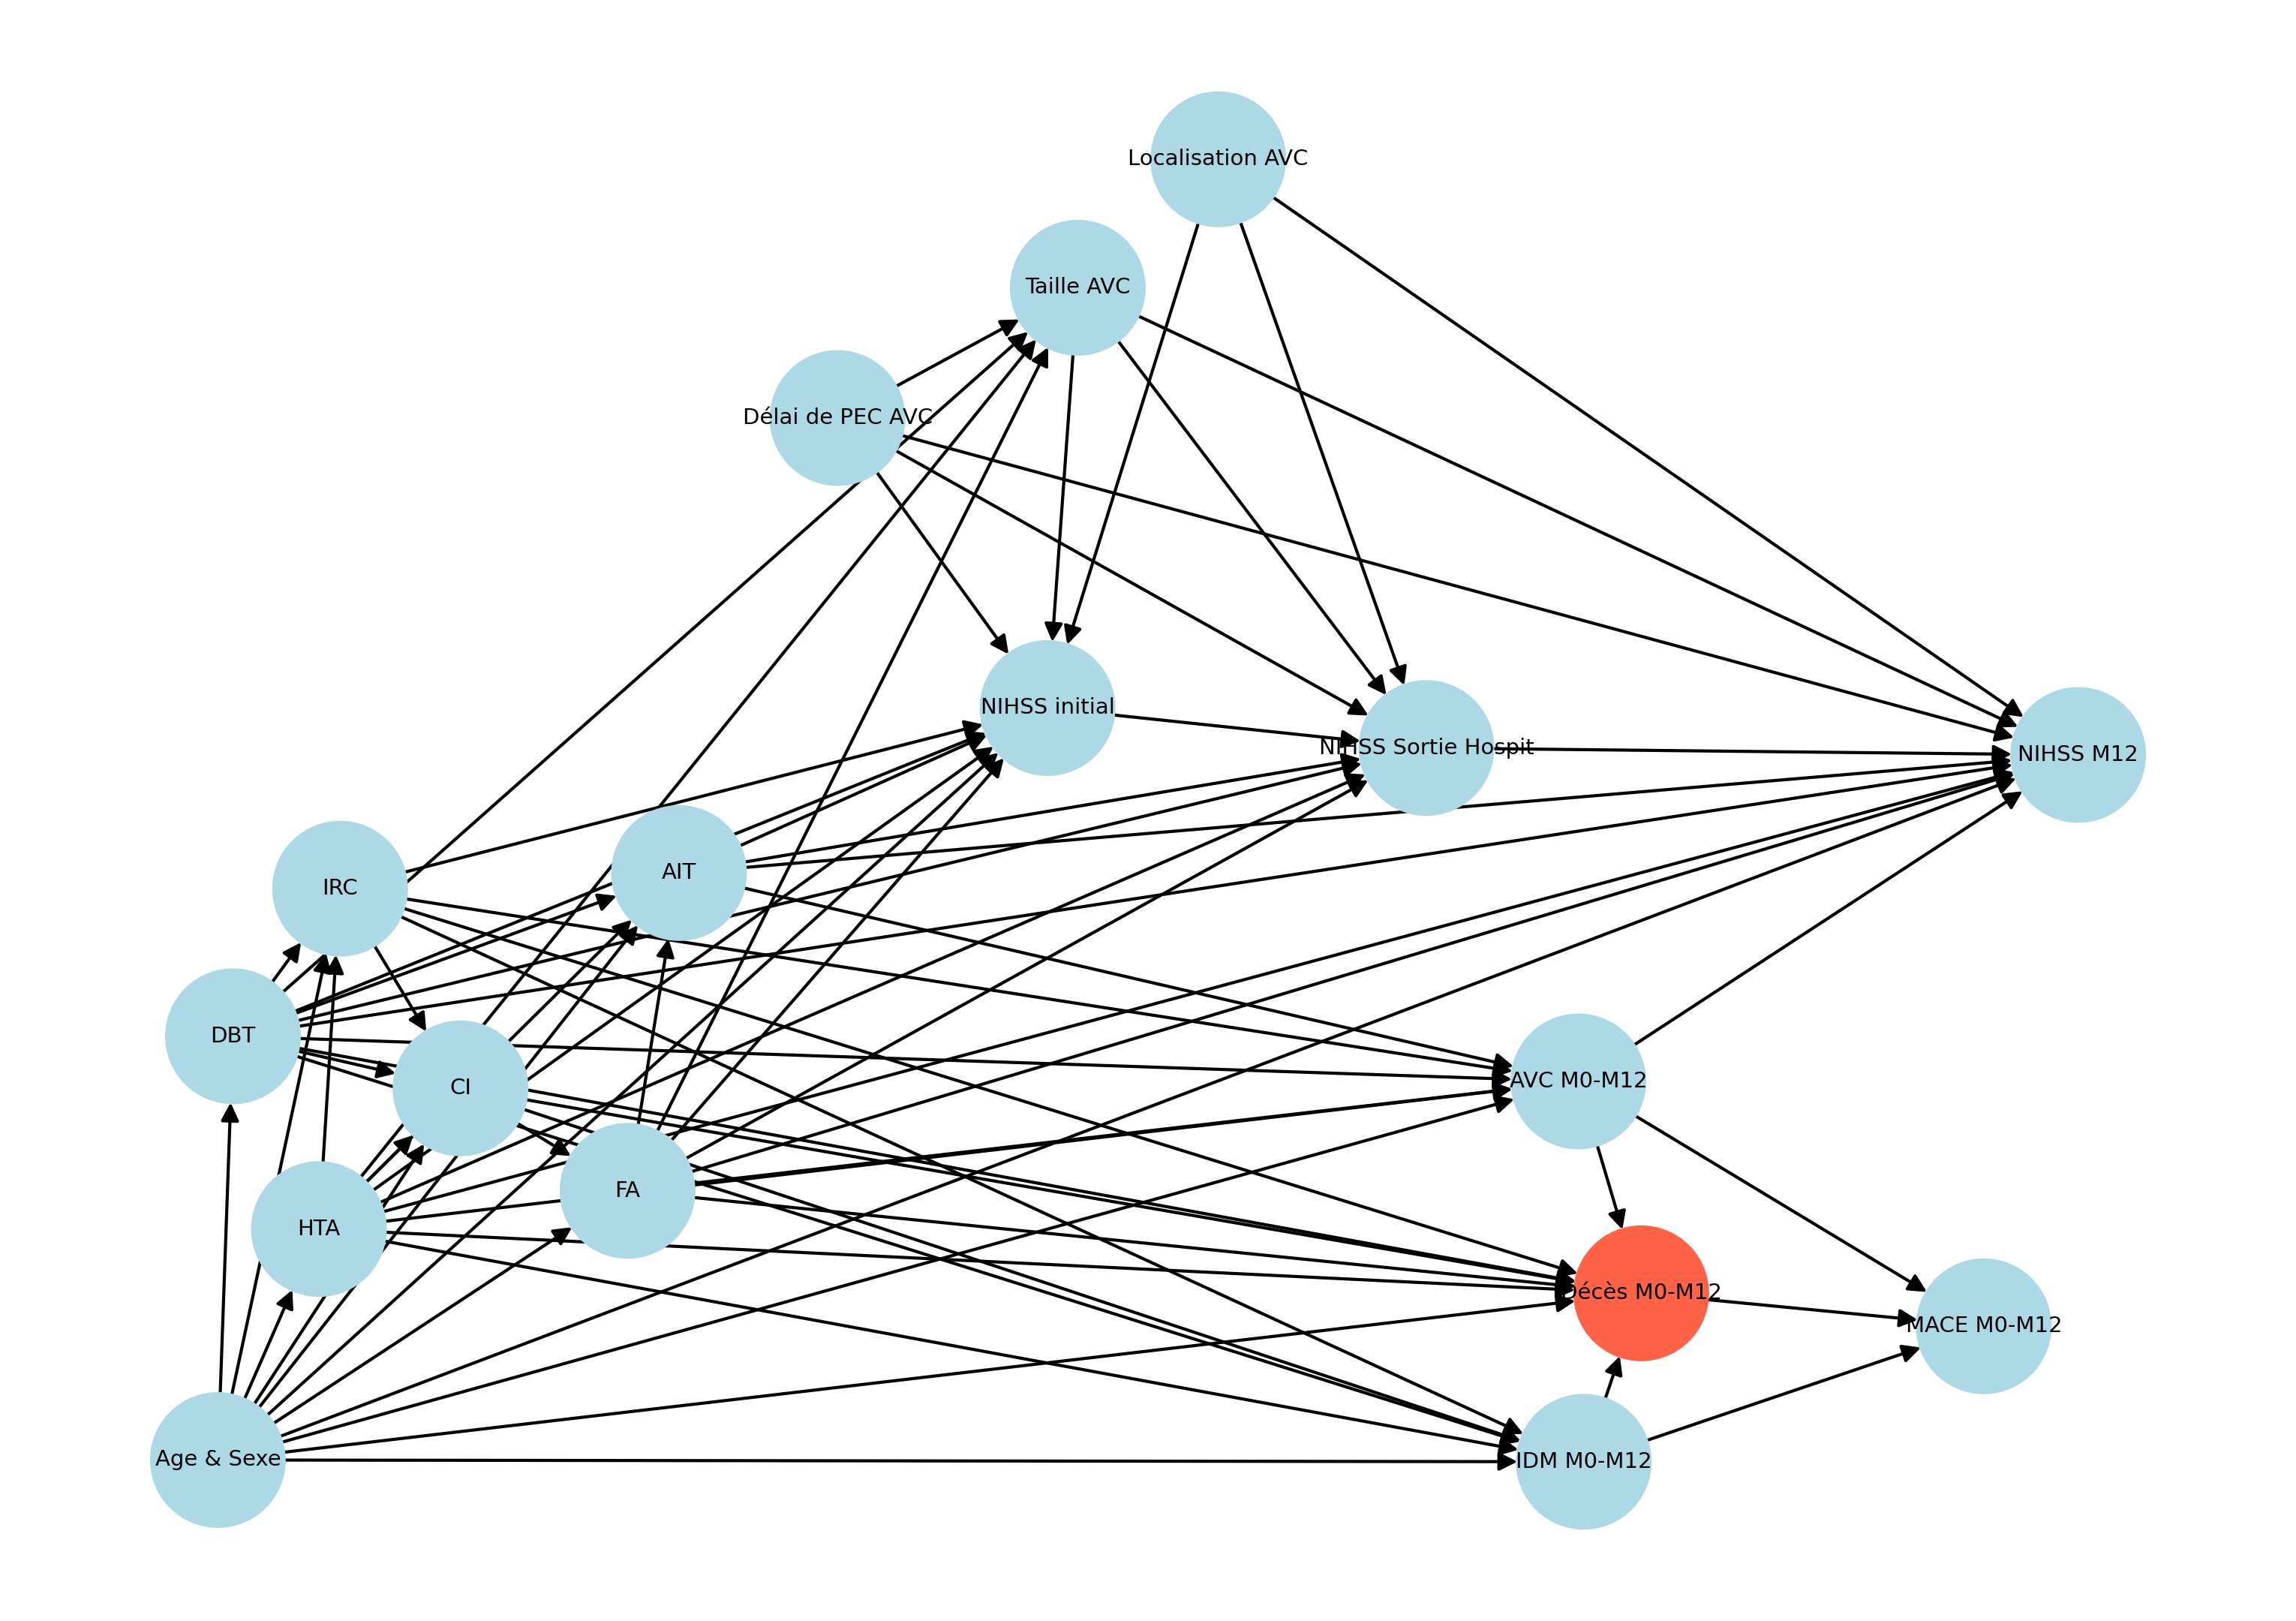

In [13]:
display(Image(filename="DAG_Death_12Month.png"))

Avant de choisir quelles variables mettre dans un modèle, il faut **expliciter les hypothèses causales** : le coefficient d'une variable n'a pas le même sens selon que les autres variables sont des confondants, des médiateurs ou des colliders.

**Lecture du DAG.**

- **Âge & Sexe** forment un seul nœud, sans parent. Ils influencent toutes les comorbidités (HTA, diabète, IRC, cardiopathie ischémique, FA, AIT), le décès, la récidive d'AVC, l'IDM et le NIHSS.
- **Les comorbidités** sont reliées entre elles : DBT → CI, IRC, AIT ; HTA → CI, IRC, AIT ; IRC → CI ; CI → FA ; FA → AIT.
- **Le décès** a pour causes directes : Âge & Sexe, HTA, DBT, IRC, CI, FA, l'IDM et la récidive d'AVC. L'AIT n'agit sur le décès que par la récidive d'AVC.
- **Le NIHSS initial, la taille et la localisation de l'AVC et le délai de prise en charge** n'ont aucune flèche vers le décès. Ils n'influencent que les NIHSS (initial, sortie, M12).

> **Question 3.** À partir de ce DAG :
> 1. Pour estimer l'**effet total du diabète** sur la mortalité à 12 mois, sur quelles variables faut-il ajuster ? Même question pour l'**insuffisance rénale chronique (IRC)**.
> 2. Faut-il ajuster sur le NIHSS à l'admission, la taille ou la localisation de l'AVC, le délai de prise en charge ?

> *Réponse :*


## 4. Régression logistique avec **une variable catégorielle** : le sexe

### 4.1 Rappels théoriques

Soit $p_i = P(Y_i = 1 \mid X_i)$ la probabilité de décès du patient $i$. Le modèle logistique suppose une relation **linéaire sur l'échelle logit** :

$$
\text{logit}(p_i) = \ln\!\left(\frac{p_i}{1-p_i}\right) = \beta_0 + \beta_1 x_i
\qquad\Longleftrightarrow\qquad
p_i = \frac{1}{1+e^{-(\beta_0+\beta_1 x_i)}}
$$

Il faut maîtriser **quatre échelles** et savoir passer de l'une à l'autre :

| Échelle | Définition | Valeurs possibles |
|---|---|---|
| Probabilité (risque) | $p$ | 0 à 1 |
| **Odds** (cote) | $p/(1-p)$ | 0 à $+\infty$ |
| **Log-odds** (logit) | $\ln\big(p/(1-p)\big)$ | $-\infty$ à $+\infty$ |
| **Odds ratio** | rapport de deux odds | 0 à $+\infty$ |

**Comment lire les coefficients :**

- $\beta_0$ (intercept) = **log-odds** de décès quand toutes les variables valent 0 (le « patient de référence »). $e^{\beta_0}$ = odds de référence. $\text{expit}(\beta_0)$ = probabilité de référence.
- $\beta_1$ = **différence de log-odds** entre deux patients qui diffèrent d'**une unité** de $x$. $e^{\beta_1}$ = **odds ratio** (OR) associé à cette unité.
- OR $>1$ : augmentation des odds de décès ; OR $<1$ : diminution ; OR $=1$ : pas d'association.
- L'effet est **additif sur l'échelle log-odds** et donc **multiplicatif sur l'échelle des odds**.

### 4.2 Calcul « à la main » à partir du tableau croisé

Avant d'ajuster le modèle, calculons l'odds ratio du sexe directement sur le tableau 2×2.

In [ ]:
tab = pd.crosstab(df["sex"], df[Y])
tab.columns = ["Vivant", "Décédé"]
display(tab)

# Calculer les odds et l'odds ration 

,Vivant,Décédé
sex,,
Male,544,68
Female,486,105


Odds de décès — hommes : 0.1250
Odds de décès — femmes : 0.2160
Odds ratio (F vs H)     : 1.7284
log(OR)                 : 0.5472


### 4.3 Ajustement du modèle logistique

On ajuste $\text{logit}(p_i) = \beta_0 + \beta_1\,\mathbb{1}[\text{sexe}_i = \text{Femme}]$ avec `smf.logit`.

In [ ]:
# model logistique avec smf.logit().fit() ; .summary()


Optimization terminated successfully.
         Current function value: 0.407294
         Iterations 6
                             Logit Regression Results                             
Dep. Variable:     death_within_12_months   No. Observations:                 1203
Model:                              Logit   Df Residuals:                     1201
Method:                               MLE   Df Model:                            1
Date:                    Tue, 03 Nov 2026   Pseudo R-squ.:                 0.01098
Time:                            05:53:12   Log-Likelihood:                -489.98
converged:                           True   LL-Null:                       -495.41
Covariance Type:                nonrobust   LLR p-value:                 0.0009742
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept        -2.0794      0.129    -16.167      0.000      -2.332 

In [12]:
tableau_or(m_sex)

,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
Intercept,-2.079,0.125,0.097,0.161,0.000
sex[T.Female],0.547,1.728,1.244,2.401,0.001


> **Question 4.** Vérifiez que `exp(coef)` du sexe retrouve l'OR calculé à la main. Puis **interprétez** :
> 1. l'intercept, sur les trois échelles (log-odds, odds, probabilité) ;
> 2. le coefficient `sex[T.Female]`, sur l'échelle log-odds puis sous forme d'OR avec son IC95 % ;
> 3. Que représente la p-value associée ?

In [ ]:
# exponentielle avec np.exp() ; récupération paramètres avec .params


Intercept : log-odds = -2.079 ; odds = 0.125 ; probabilité = 0.111
Sexe F    : log-odds = 0.547 ; OR = 1.728
Probabilité de décès, femmes : 0.178  (vs 0.178 observé)


> *Réponse :*


## 5. Régression logistique avec **une variable quantitative** : l'âge

### 5.1 Modèle brut

$$\text{logit}(p_i) = \beta_0 + \beta_1\,\text{age}_i$$

In [ ]:
# Ecrire ce model et modèle le tableau des OR


Optimization terminated successfully.
         Current function value: 0.393185
         Iterations 6


,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
Intercept,-5.689,0.003,0.001,0.012,0.000
age_at_inclusion,0.051,1.052,1.036,1.069,0.000


> **Question 5.**
> 1. Interprétez le coefficient de `age_at_inclusion` (log-odds, puis OR avec IC95 %).
> 2. L'intercept (−5,69) a-t-il une signification clinique ? Pourquoi ?
> 3. Quel est l'OR pour **10 ans** d'âge supplémentaires ? (Attention : on ne multiplie pas l'OR par 10 !)

In [ ]:
# .params[] et intervalle de confiance avec .conf_int()


OR par année    : 1.052  IC95% [1.036 ; 1.069]
OR pour 10 ans  : 1.668  IC95% [1.428 ; 1.948]
(à ne pas faire : 1.052 x 10 = 10.52  ; la bonne opération est 1.052 ** 10 = 1.668)


> *Réponse :* 


### 5.2 Changer d'unité et centrer la variable

On définit `age_c = (âge − 75) / 10` : l'âge est exprimé en **décennies** et centré sur 75 ans (≈ âge moyen). Ce changement de variable ne change **pas** le modèle (mêmes prédictions, même log-vraisemblance). Il sert à trois choses :

1. **Changer l'unité** : la pente devient l'OR **par décennie**, plus parlant qu'un OR par année (c'est le gain principal).
2. **Donner un sens à l'intercept dans un modèle simple** : ici, il devient le log-odds de décès d'un patient de 75 ans, âge réellement observé. **Attention** : dans un modèle avec plusieurs variables, l'intercept est le log-odds du *profil de référence* (toutes les variables à 0 ou à la modalité de référence), parfois rare ou inexistant. On ne l'interprète alors généralement pas : on rapporte les OR, et on utilise l'intercept seulement pour calculer des probabilités prédites.


In [20]:
df["age_c"] = (df["age_at_inclusion"] - 75) / 10

m_age_c = smf.logit("death_within_12_months ~ age_c", data=df).fit()
display(tableau_or(m_age_c))
print("Log-vraisemblance modèle brut :", round(m_age.llf, 4), "| modèle centré :", round(m_age_c.llf, 4), "(identiques)")
print(f"\nProbabilité de décès à 75 ans : {expit(m_age_c.params['Intercept']):.3f}")

Optimization terminated successfully.
         Current function value: 0.393185
         Iterations 6


,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
Intercept,-1.853,0.157,0.132,0.186,0.000
age_c,0.511,1.668,1.428,1.948,0.000


Log-vraisemblance modèle brut : -473.0011 | modèle centré : -473.0011 (identiques)

Probabilité de décès à 75 ans : 0.135


**Comment interprétez-vous l'intercept ?**

> *Réponse :*

### 5.3 Vérifier l'hypothèse de linéarité du logit

Le modèle suppose que l'effet de l'âge est **linéaire sur l'échelle logit**. On le vérifie en comparant le logit observé par classe d'âge à la droite du modèle.

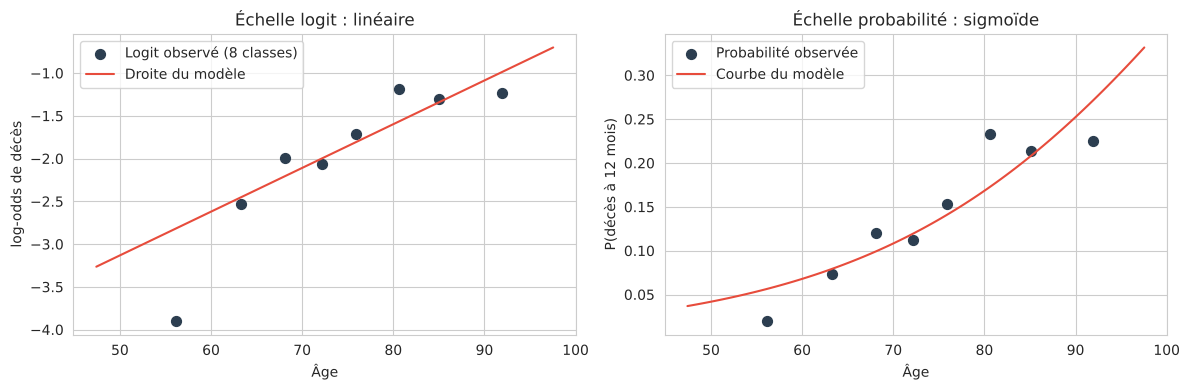

In [ ]:
classes = pd.qcut(df["age_at_inclusion"], 8)
obs = df.groupby(classes, observed=True).agg(age=("age_at_inclusion", "mean"), p=(Y, "mean"), n=(Y, "size"))
obs["logit_obs"] = logit(obs["p"])

grille = pd.DataFrame({"age_at_inclusion": np.linspace(df.age_at_inclusion.min(), df.age_at_inclusion.max(), 100)})
grille["lp"] = m_age.params["Intercept"] + m_age.params["age_at_inclusion"] * grille["age_at_inclusion"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(obs["age"], obs["logit_obs"], color=C1, s=50, label="Logit observé (8 classes)")
axes[0].plot(grille["age_at_inclusion"], grille["lp"], color=C2, label="Droite du modèle")
axes[0].set_xlabel("Âge"); axes[0].set_ylabel("log-odds de décès"); axes[0].set_title("Échelle logit : linéaire"); axes[0].legend()

axes[1].scatter(obs["age"], obs["p"], color=C1, s=50, label="Probabilité observée")
axes[1].plot(grille["age_at_inclusion"], expit(grille["lp"]), color=C2, label="Courbe du modèle")
axes[1].set_xlabel("Âge"); axes[1].set_ylabel("P(décès à 12 mois)"); axes[1].set_title("Échelle probabilité : sigmoïde"); axes[1].legend()
plt.tight_layout(); plt.show()

> **Question 6.** L'hypothèse de linéarité vous semble-t-elle raisonnable ? Observez que sur l'échelle probabilité, la **différence** de risque entre 55 et 65 ans n'est pas la même qu'entre 80 et 90 ans alors que l'**OR est constant** : que faut-il en retenir pour l'interprétation ?

> *Réponse :* 

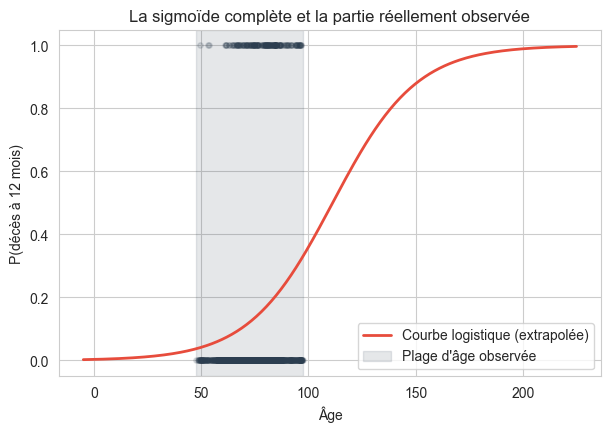

In [25]:
age_c_grid = np.linspace(-8, 15, 300)     # âge de -5 à +220 ans : extrapolation, uniquement pour visualiser le S
p = expit(m_age_c.params["Intercept"] + m_age_c.params["age_c"] * age_c_grid)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(75 + 10 * age_c_grid, p, color=C2, lw=2, label="Courbe logistique (extrapolée)")
ax.axvspan(df.age_at_inclusion.min(), df.age_at_inclusion.max(), color=C1, alpha=0.12, label="Plage d'âge observée")
ax.scatter(df["age_at_inclusion"], df["death_within_12_months"], alpha=0.15, s=15, color=C1)
ax.set_xlabel("Âge"); ax.set_ylabel("P(décès à 12 mois)")
ax.set_title("La sigmoïde complète et la partie réellement observée")
ax.legend(); plt.show()

> **Exercice 3.** Avec le modèle `m_age_c` (Attention ce sont des décennies), calculez (a) l'OR pour **5 ans** supplémentaires avec son IC95 % ; (b) les probabilités prédites de décès à **60, 75 et 90 ans**.

In [ ]:
# Utilisez la fonction .predict() pour prédire l'OR, l'âge doit être dans la même unité


OR pour 5 ans : 1.291  IC95% [1.195 ; 1.396]
   âge  P(décès)
0   60     0.068
1   75     0.135
2   90     0.252


## 6. Régression logistique avec **une catégorielle et une quantitative, sans interaction**

### 6.1 Spécification

$$\text{logit}(p_i) = \beta_0 + \beta_1\,\text{age\_c}_i + \beta_2\,\mathbb{1}[\text{sexe}_i = \text{Femme}]$$

Ce modèle suppose que l'effet de l'âge est **le même** chez les hommes et chez les femmes, et que l'effet du sexe est **le même à tous les âges** (deux droites **parallèles** sur l'échelle logit, décalées de $\beta_2$).

In [ ]:
# Ecrivez le model multiple sans interaction avec smf.logit()
# Affichez le tableau des OR

Optimization terminated successfully.
         Current function value: 0.393133
         Iterations 6


,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
Intercept,-1.887,0.151,0.117,0.196,0.000
sex[T.Female],0.066,1.069,0.739,1.546,0.725
age_c,0.498,1.646,1.385,1.954,0.000


> **Question 7.** Interprétez chaque ligne du tableau :
> 1. l'intercept ; 2. `age_c` ; 3. `sex[T.Female]`.
>
> Précisez à chaque fois **« pour qui »** (quel patient de référence, à quoi est-on égal ?).

> *Réponse :* 


### 6.2 Comparer l'OR brut et l'OR ajusté : la confusion

In [ ]:
# Comparez les OR du sex seul vs ajusté sur l'âge. Récupérez les coef des modèles


,OR brut (sexe seul),OR ajusté sur l'âge
Femme vs Homme,1.728,1.069


Variation relative du coefficient : -88 %

Âge moyen selon le sexe :
         mean    std
sex                 
Male   69.200 10.200
Female 79.300  9.800


> **Question 8.** L'OR du sexe passe de 1,73 à 1,07 après ajustement sur l'âge. Expliquez ce phénomène. Est-ce un exemple de confusion ? Quelle est la bonne phrase pour présenter le résultat dans un article ?

> *Réponse :* 

> **Exercice 4.** Calculez les odds pour quatre profils : homme et femme de **65 ans**, homme et femme de **85 ans**. Vérifiez que l'**OR du sexe** est identique aux deux âges.

In [ ]:
# Utilisez fonction .predict() 

,sex,age,age_c,p_pred,odds
0,Male,65,-1.000,0.084,0.092
1,Female,65,-1.000,0.090,0.098
2,Male,85,1.000,0.200,0.249
3,Female,85,1.000,0.210,0.266


65 ans : OR femme/homme = 1.069
85 ans : OR femme/homme = 1.069


> *Réponse :* 

## 7. Régression logistique avec **une catégorielle et une quantitative, avec interaction**

### 7.1 Spécification

On autorise maintenant l'effet de l'âge à **différer** selon le sexe :

$$\text{logit}(p_i) = \beta_0 + \beta_1\,\text{age\_c}_i + \beta_2\,F_i + \beta_3\,(\text{age\_c}_i \times F_i)$$

avec $F_i = \mathbb{1}[\text{sexe}_i = \text{Femme}]$. La formule `age_c * sex` développe automatiquement en `age_c + sex + age_c:sex`.

In [ ]:
# Ecrire le modèle avec intéraction et montrer le tableau des OR

Optimization terminated successfully.
         Current function value: 0.392890
         Iterations 7


,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
Intercept,-1.874,0.153,0.118,0.199,0.000
sex[T.Female],0.094,1.099,0.758,1.591,0.619
age_c,0.576,1.779,1.363,2.323,0.000
age_c:sex[T.Female],-0.136,0.873,0.616,1.238,0.446


### 7.2 Lire les coefficients d'un modèle avec interaction

Avec une interaction, **les coefficients « principaux » ne sont plus des effets globaux** : ils sont des effets **conditionnels** à la valeur de l'autre variable.

| Coefficient | Se lit comme… | Pour… |
|---|---|---|
| $\beta_0$ | log-odds de base | **homme de 75 ans** ($F=0$, age_c $=0$) |
| $\beta_1$ (`age_c`) | effet de l'âge **chez les hommes** (pente de la droite de référence) | $F = 0$ **uniquement** |
| $\beta_2$ (`sex[T.Female]`) | effet du sexe **à 75 ans** | age_c $= 0$ **uniquement** |
| $\beta_3$ (`age_c:sex[T.Female]`) | **différence** des pentes d'âge entre femmes et hommes ; $e^{\beta_3}$ = **rapport de deux OR** | — |

Et donc :

- OR de l'âge (par décennie) **chez les hommes** $= e^{\beta_1}$ ;
- OR de l'âge (par décennie) **chez les femmes** $= e^{\beta_1+\beta_3}$ ;
- OR du sexe **à l'âge $a$** $= e^{\beta_2 + \beta_3\,\text{age\_c}(a)}$.

> **Question 9.** Interprétez $\beta_1$, $\beta_2$ et $\beta_3$ pour ce modèle. Pourquoi est-il **faux** de dire « l'OR de l'âge est de 1,78 » sans précision ?

> *Réponse :* 


### 7.3 Obtenir les OR « par sexe » avec leurs IC : combinaisons linéaires de coefficients

L'IC de $e^{\beta_1+\beta_3}$ ne se déduit pas des IC séparés de $\beta_1$ et $\beta_3$ : il faut la variance de la **somme** (qui tient compte de la covariance). On utilise `t_test` sur une combinaison linéaire (équivalent du `lincom` de Stata).

In [36]:
# OR de l'âge (par décennie) chez les femmes : beta1 + beta3
comb = m_int.t_test("age_c + age_c:sex[T.Female] = 0") # Test somme des coefficients = 0 ; fournit ensuite l'IC !
b, (lo, hi) = comb.effect[0], comb.conf_int()[0]
print(f"OR âge chez les FEMMES : {np.exp(b):.3f}  IC95% [{np.exp(lo):.3f} ; {np.exp(hi):.3f}]  (p = {comb.pvalue:.2g})")

# OR de l'âge chez les hommes : beta1 directement
b, (lo, hi) = m_int.params["age_c"], m_int.conf_int().loc["age_c"]
print(f"OR âge chez les HOMMES : {np.exp(b):.3f}  IC95% [{np.exp(lo):.3f} ; {np.exp(hi):.3f}]")

# Vérification : on change la référence du sexe (Female) → le coefficient 'age_c' devient directement l'effet chez les femmes
df_inv = df.assign(sex=pd.Categorical(df["sex"].astype(str), categories=["Female", "Male"]))
m_inv = smf.logit("death_within_12_months ~ age_c * sex", data=df_inv).fit(disp=0)
# OR et IC95% de l'âge chez les femmes (groupe de référence)
b = m_inv.params["age_c"]
lo, hi = m_inv.conf_int().loc["age_c"]

print(f"\nVérification (référence = Femme) : OR âge = {np.exp(b):.3f} ; " f"IC95% [{np.exp(lo):.3f} ; {np.exp(hi):.3f}]")

OR âge chez les FEMMES : 1.553  IC95% [1.240 ; 1.946]  (p = 0.00013)
OR âge chez les HOMMES : 1.779  IC95% [1.363 ; 2.323]

Vérification (référence = Femme) : OR âge = 1.553 ; IC95% [1.240 ; 1.946]


> **Exercice 5.** Calculez l'**OR du sexe (femme vs homme)** à **65 ans** et à **85 ans** avec IC95 %, grâce à `t_test`. (Indice : OR du sexe à l'âge $a$ = $e^{\beta_2+\beta_3\,\text{age\_c}(a)}$ ; pour 65 ans, age_c = −1 ; pour 85 ans, age_c = +1.)

In [ ]:
#

65 ans : OR sexe (F vs H) = 1.258  IC95% [0.721 ; 2.195]  p = 0.42
75 ans : OR sexe (F vs H) = 1.099  IC95% [0.758 ; 1.591]  p = 0.62
85 ans : OR sexe (F vs H) = 0.959  IC95% [0.607 ; 1.514]  p = 0.86


> *Réponse :* 

### 7.4 Visualiser l'interaction

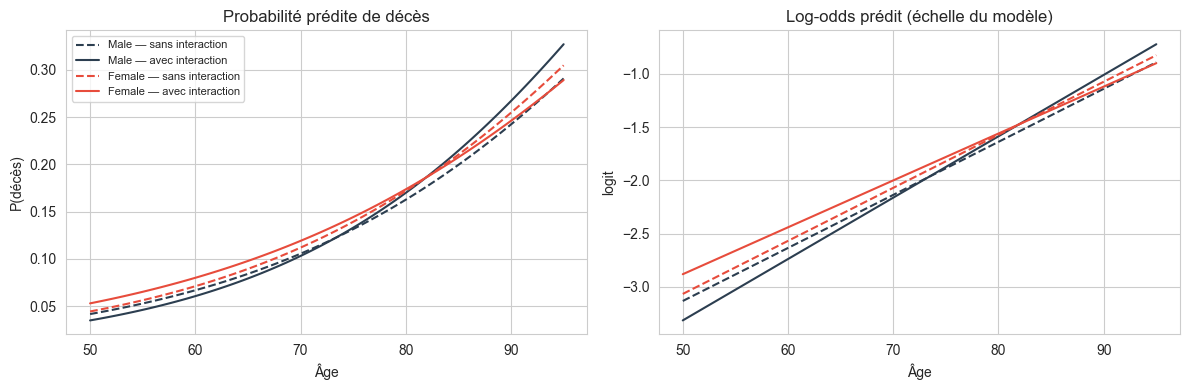

In [37]:
ages = np.linspace(50, 95, 100)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for sexe, couleur in [("Male", C1), ("Female", C2)]:
    g = pd.DataFrame({"age_c": (ages - 75) / 10, "sex": pd.Categorical([sexe] * len(ages), categories=["Male", "Female"])})
    for modele, ls, lab in [(m_adj, "--", "sans interaction"), (m_int, "-", "avec interaction")]:
        p = modele.predict(g)
        axes[0].plot(ages, p, color=couleur, ls=ls, label=f"{sexe} — {lab}")
        axes[1].plot(ages, logit(p), color=couleur, ls=ls)
axes[0].set_title("Probabilité prédite de décès"); axes[0].set_xlabel("Âge"); axes[0].set_ylabel("P(décès)"); axes[0].legend(fontsize=8)
axes[1].set_title("Log-odds prédit (échelle du modèle)"); axes[1].set_xlabel("Âge"); axes[1].set_ylabel("logit")
plt.tight_layout(); plt.show()

> **Question 10.**
> 1. Sur l'échelle logit (graphique de droite), comment reconnaît-on l'absence d'interaction ? Que montrent les droites en trait plein ?
> 2. Le terme d'interaction est-il significatif ? Quelle décision prenez-vous (conserver ou non l'interaction) et pourquoi ?
> 3. Dans un modèle avec interaction **non centré** sur l'âge, que deviendrait le coefficient `sex[T.Female]` ?

> *Réponse :* 


## 8. Ajout d'une variable supplémentaire : test d'interaction, puis test du coefficient (Wald et rapport de vraisemblance)

On souhaite maintenant ajouter une comorbidité, **le diabète**, au modèle $\{\text{âge\_c}, \text{sexe}\}$.

**Démarche en deux temps :**

1. **Tester les interactions** de la nouvelle variable avec les variables déjà présentes (diabète × âge, diabète × sexe). *Si une interaction est retenue*, l'effet du diabète n'est plus un OR unique.
2. **Si pas d'interaction**, tester le **coefficient** du diabète dans le modèle additif.

Chaque test peut se faire de deux façons :

| | **Test de Wald** | **Rapport de vraisemblance (LRT)** |
|---|---|---|
| Principe | $z = \hat\beta / SE(\hat\beta)$ : est-ce que $\hat\beta$ est « loin » de 0 ? | Compare la vraisemblance du modèle **avec** et **sans** le terme |
| Modèles à ajuster | **Un seul** (le modèle complet) | **Deux** (restreint $m_0$ et complet $m_1$) |
| Statistique | $z^2 \sim \chi^2_1$ (1 coefficient) ou Wald joint $\chi^2_k$ ($k$ coefficients) | $\text{LRT} = 2(\ell_1 - \ell_0) \sim \chi^2_k$ ($k$ = nb. de paramètres en plus) |
| Qualité | Approximation asymptotique, **dépend de la paramétrisation**, peu fiable si effet très grand ou petit effectif | Plus fiable en petit échantillon, **invariant par reparamétrisation** |
| Usage | Rapide, donne directement p et IC | Référence pour comparer des modèles emboîtés, tester **plusieurs coefficients à la fois** |

Les deux sont **asymptotiquement équivalents** : avec un échantillon large et un effet « raisonnable », ils donnent des p-values proches.

### 8.1 Description préalable

In [38]:
print(df.groupby("diabetes")[Y].agg(n="size", deces="sum", mortalite="mean").round(3))
print("\nRépartition du diabète selon le sexe :")
print(pd.crosstab(df["sex"], df["diabetes"], normalize="index").round(3))
print("\nÂge moyen selon le diabète :")
print(df.groupby("diabetes")["age_at_inclusion"].mean().round(1))

            n  deces  mortalite
diabetes                       
0         720     63      0.088
1         483    110      0.228

Répartition du diabète selon le sexe :
diabetes     0     1
sex                 
Male     0.580 0.420
Female   0.618 0.382

Âge moyen selon le diabète :
diabetes
0   74.600
1   73.400
Name: age_at_inclusion, dtype: float64


### 8.2 Étape 1 — Y a-t-il une interaction du diabète avec l'âge ou le sexe ?

On ajuste le **modèle complet** avec les deux interactions et le **modèle additif** :

- $m_0$ : `age_c + sex + diabetes`
- $m_1$ : `age_c + sex + diabetes + diabetes:age_c + diabetes:sex` (2 paramètres de plus)

**Version Wald.** Un seul modèle ($m_1$). Test de chaque coefficient d'interaction (z) et **test de Wald joint** des deux coefficients à la fois.

In [39]:
m0 = smf.logit("death_within_12_months ~ age_c + sex + diabetes", data=df).fit(disp=0)
m1 = smf.logit("death_within_12_months ~ age_c + sex + diabetes + diabetes:age_c + diabetes:sex", data=df).fit(disp=0)

display(tableau_or(m1))

# Wald joint : H0 : les DEUX interactions sont nulles
w = m1.wald_test("diabetes:age_c = 0, diabetes:sex[T.Female] = 0", scalar=True)
print(f"\n[WALD joint, 2 ddl]  chi2 = {float(w.statistic):.3f}  p = {float(w.pvalue):.3f}")

,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
Intercept,-2.551,0.078,0.050,0.121,0.000
sex[T.Female],0.181,1.199,0.655,2.194,0.556
age_c,0.475,1.608,1.218,2.123,0.001
diabetes,1.277,3.586,2.073,6.204,0.000
diabetes:sex[T.Female],-0.126,0.882,0.406,1.913,0.750
diabetes:age_c,0.116,1.123,0.783,1.611,0.527



[WALD joint, 2 ddl]  chi2 = 0.403  p = 0.817


**Version rapport de vraisemblance.** Deux modèles emboîtés ($m_0 \subset m_1$) ; on compare leurs log-vraisemblances.

In [40]:
print("[LRT : interactions du diabète]")
display(lrt(m0, m1).to_frame("valeur"))

[LRT : interactions du diabète]


,valeur
-2 log-vraisemblance m0,893.386
-2 log-vraisemblance m1,892.984
Statistique LRT,0.402
ddl,2.000
p-value,0.818


> **Question 11.** Que concluez-vous sur l'interaction du diabète avec l'âge et le sexe ? Les deux méthodes (Wald joint et LRT) concordent-elles ? Quel modèle retenez-vous ?

> *Réponse :* 

### 8.3 Étape 2 — Test du coefficient du diabète dans le modèle additif

**Version Wald** : la p-value du coefficient `diabetes` dans $m_0$.

In [42]:
res0 = tableau_or(m0)
display(res0)
z = m0.params["diabetes"] / m0.bse["diabetes"]
print(f"[WALD] z = {z:.3f} ; p = {m0.pvalues['diabetes']:.2e}")

,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
Intercept,-2.535,0.079,0.056,0.111,0.000
sex[T.Female],0.103,1.109,0.760,1.617,0.591
age_c,0.545,1.725,1.445,2.058,0.000
diabetes,1.245,3.472,2.456,4.908,0.000


[WALD] z = 7.050 ; p = 1.79e-12


**Version rapport de vraisemblance** : on compare $m_{\text{base}}$ (âge, sexe) et $m_0$ (âge, sexe, **diabète**).

In [43]:
m_base = smf.logit("death_within_12_months ~ age_c + sex", data=df).fit(disp=0)   # = m_adj
print("[LRT : effet du diabète]")
display(lrt(m_base, m0).to_frame("valeur"))
print(f"\nAIC modèle sans diabète : {m_base.aic:.1f} | avec diabète : {m0.aic:.1f}  (plus petit = meilleur)")

[LRT : effet du diabète]


,valeur
-2 log-vraisemblance m0,945.878
-2 log-vraisemblance m1,893.386
Statistique LRT,52.493
ddl,1.000
p-value,0.000



AIC modèle sans diabète : 951.9 | avec diabète : 901.4  (plus petit = meilleur)


> **Question 12.**
> 1. Interprétez le coefficient du diabète (OR, IC95 %) **dans ce modèle**. Précisez « pour qui » et « à quoi est-on égal ».
> 2. Comparez les p-values pour Wald et LRT.
> 3. Comparez les OR du sexe et de l'âge avant et après ajout du diabète. Le diabète est-il un facteur de confusion pour ces variables ?

> *Réponse :* 


In [32]:
pd.DataFrame({
    "OR sexe (F vs H) — sans diabète": [np.exp(m_base.params["sex[T.Female]"])],
    "OR sexe (F vs H) — avec diabète": [np.exp(m0.params["sex[T.Female]"])],
    "OR âge (par décennie) — sans diabète": [np.exp(m_base.params["age_c"])],
    "OR âge (par décennie) — avec diabète": [np.exp(m0.params["age_c"])],
}).T.rename(columns={0: "OR"})

,OR
OR sexe (F vs H) — sans diabète,1.069
OR sexe (F vs H) — avec diabète,1.109
OR âge (par décennie) — sans diabète,1.646
OR âge (par décennie) — avec diabète,1.725


### 8.4 Exercice : le cas de l'insuffisance rénale chronique (IRC)

> **Exercice 6.** Refaites la démarche en deux temps pour `chronic_kidney_disease` :
> 1. Tester l'interaction **IRC × sexe** avec **Wald** *et* **LRT** (on se limite à l'interaction avec le sexe) ;
> 2. Selon le résultat, tester le coefficient de l'IRC, avec Wald *et* LRT ;
> 3. Conclure. Que faire si l'interaction est « limite » (p ≈ 0,07) ?

In [ ]:
# A vous de jouer !


--- Interaction IRC x sexe ---
WALD : p = 0.075


,LRT
-2 log-vraisemblance m0,912.077
-2 log-vraisemblance m1,908.900
Statistique LRT,3.177
ddl,1.000
p-value,0.075


--- Coefficient de l'IRC (modèle additif) ---


,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
chronic_kidney_disease,1.331,3.783,2.468,5.800,0.000


,LRT
-2 log-vraisemblance m0,945.878
-2 log-vraisemblance m1,912.077
Statistique LRT,33.801
ddl,1.000
p-value,0.000


OR IRC chez les hommes : 5.66 [3.09 ; 10.38]
OR IRC chez les femmes : 2.63 [1.45 ; 4.77]


> *Réponse :* 

### 8.5 Piège : quand le test de Wald et le modèle échouent (séparation)

Rappelez-vous : les 16 patients avec un antécédent d'AIT sont **tous des femmes**. Que se passe-t-il si l'on essaie de tester une interaction AIT × sexe ?

In [44]:
try:
    m_tia = smf.logit("death_within_12_months ~ age_c + sex * transient_ischemic_attack", data=df).fit(disp=0)
    print(tableau_or(m_tia))
except Exception as e:
    print("Le modèle ne peut pas être ajusté :", type(e).__name__, "-", e)

# En revanche, l'effet additif de l'AIT est estimable (mais très imprécis)
m_tia_add = smf.logit("death_within_12_months ~ age_c + sex + transient_ischemic_attack", data=df).fit(disp=0)
display(tableau_or(m_tia_add).loc[["transient_ischemic_attack"]])
print("LRT :"); display(lrt(m_base, m_tia_add).to_frame("valeur"))

Le modèle ne peut pas être ajusté : LinAlgError - Singular matrix


,coef (log-odds),OR = exp(coef),IC95% OR bas,IC95% OR haut,p-value (Wald)
transient_ischemic_attack,0.579,1.784,0.557,5.715,0.330


LRT :


,valeur
-2 log-vraisemblance m0,945.878
-2 log-vraisemblance m1,945.012
Statistique LRT,0.867
ddl,1.000
p-value,0.352


> *Réponse :*